In [46]:
import pandas as pd

In [47]:
data = pd.read_csv("/content/sentiment_analysis.csv", header= None)

In [48]:
data.drop([0,1,2,3,6], axis=1, inplace=True)

In [49]:
data.head()

,4,5
0,text,sentiment
1,What a great day!!! Looks like dream.,positive
2,"I feel sorry, I miss you here in the sea beach",positive
3,Don't angry me,negative
4,We attend in the class just for listening teac...,negative


In [50]:
data.isna().sum()

,0
4,0
5,0


In [51]:
data.duplicated().sum()

np.int64(105)

In [52]:
data.drop_duplicates(inplace=True)

In [53]:
data.rename({4:"Reviews", 5:"sentiment"}, axis=1, inplace=True)

In [54]:
data

,Reviews,sentiment
0,text,sentiment
1,What a great day!!! Looks like dream.,positive
2,"I feel sorry, I miss you here in the sea beach",positive
3,Don't angry me,negative
4,We attend in the class just for listening teac...,negative
...,...,...
495,"According to , a quarter of families under six...",negative
496,the plan to not spend money is not going well,negative
497,uploading all my bamboozle pictures of facebook,neutral
498,congratulations ! you guys finish a month ear...,positive


In [55]:
data.sentiment.value_counts()

,count
sentiment,
neutral,153
positive,132
negative,109
sentiment,1


<Axes: xlabel='sentiment'>

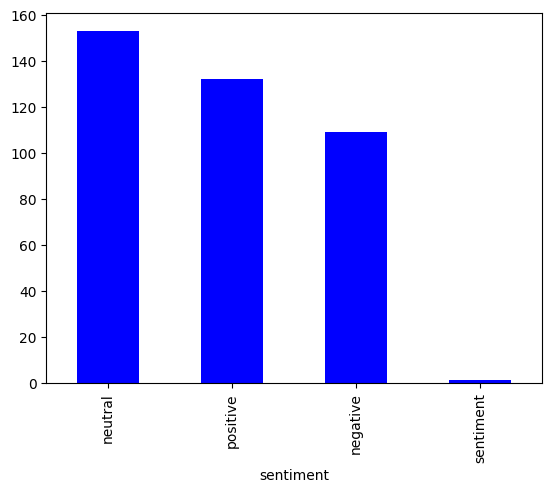

In [56]:
data.sentiment.value_counts().plot(kind="bar", color="b")

In [57]:
import re
import string
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords')

def preprocessing(text):
  text = text.lower()
  text = re.sub(r"\d", "", text)
  text = re.sub(r"\s+", " ", text)
  text = "".join([a for a in text if a not in string.punctuation])
  stop_words = set(stopwords.words("english"))
  text = " ".join([a for a in text.split() if a not in stop_words])
  return text
preprocessing(text= """The quick brown Fox, jumping over 7 lazy dogs... wait, DID it really happen? No! It's 100% false — or is it? [Yes/No]. Check out this example; 'Hello' ~ World! @Username #Tag \$Cash %Percent ^Power &Amp *Star (Open) _Under +Plus =Equal {Brace} |Pipe \Back /Slash :Colon <Less >More ?Question `Tick.""")

<>:16: SyntaxWarning: invalid escape sequence '\$'
<>:16: SyntaxWarning: invalid escape sequence '\$'
/tmp/ipykernel_1437/1487324144.py:16: SyntaxWarning: invalid escape sequence '\$'
  preprocessing(text= """The quick brown Fox, jumping over 7 lazy dogs... wait, DID it really happen? No! It's 100% false — or is it? [Yes/No]. Check out this example; 'Hello' ~ World! @Username #Tag \$Cash %Percent ^Power &Amp *Star (Open) _Under +Plus =Equal {Brace} |Pipe \Back /Slash :Colon <Less >More ?Question `Tick.""")
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


'quick brown fox jumping lazy dogs wait really happen false — yesno check example hello world username tag cash percent power amp star open plus equal brace pipe back slash colon less question tick'

In [58]:
data["Reviews"]=data["Reviews"].apply(preprocessing)

In [59]:
data

,Reviews,sentiment
0,text,sentiment
1,great day looks like dream,positive
2,feel sorry miss sea beach,positive
3,dont angry,negative
4,attend class listening teachers reading slide ...,negative
...,...,...
495,according quarter families six live poverty,negative
496,plan spend money going well,negative
497,uploading bamboozle pictures facebook,neutral
498,congratulations guys finish month early booo,positive


In [60]:
from tensorflow import keras
from tensorflow.keras.preprocessing.text import Tokenizer

In [61]:
tok = Tokenizer()

In [62]:
tok.fit_on_texts(data["Reviews"])

In [63]:
data["Reviews"] =  tok.texts_to_sequences(data['Reviews'])

In [64]:
data.sentiment.value_counts()

,count
sentiment,
neutral,153
positive,132
negative,109
sentiment,1


In [65]:
data["sentiment"] = data.sentiment.map({
    "negative" : 0,
    "positive": 1,
    "neutral": 2,
    "sentiment":4
})

In [66]:
data

,Reviews,sentiment
0,[211],4
1,"[35, 2, 49, 6, 402]",1
2,"[36, 37, 27, 212, 213]",1
3,"[7, 403]",0
4,"[404, 214, 91, 405, 406, 407, 408]",0
...,...,...
495,"[1274, 1275, 1276, 1277, 61, 1278]",0
496,"[119, 1279, 1280, 8, 30]",0
497,"[1281, 1282, 1283, 347]",2
498,"[1284, 1285, 1286, 1287, 147, 362]",1


In [67]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [79]:
import numpy as np
import pandas as pd


raw_texts = data['Reviews'].astype(str).values

lengths = data['Reviews'].astype(str).str.len().values

max_char_len = np.max(lengths)
print("Max character length:", max_char_len)


Max character length: 81


In [81]:
x = pad_sequences(data["Reviews"], maxlen=163, padding="post")
y = data["sentiment"].values

In [82]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.30, random_state= 42)

In [83]:
from tensorflow import keras
from tensorflow.keras import layers

In [101]:
vocab_size = len(tok.word_index) + 1

model = keras.Sequential([
    layers.Input(shape=(163,)),
    layers.Embedding(input_dim=vocab_size, output_dim=32),
    layers.LSTM(128, return_sequences=True),
    layers.LSTM(256),
    layers.Dense(5, activation="softmax")
])


In [102]:
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

In [103]:
model.fit(X_train, y_train, epochs=10, validation_split=0.2)

Epoch 1/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 105ms/step - accuracy: 0.3227 - loss: 1.3864 - val_accuracy: 0.5000 - val_loss: 1.0508
Epoch 2/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.3273 - loss: 1.1841 - val_accuracy: 0.5000 - val_loss: 1.0480
Epoch 3/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.2864 - loss: 1.1765 - val_accuracy: 0.2679 - val_loss: 1.1816
Epoch 4/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.3591 - loss: 1.1122 - val_accuracy: 0.5000 - val_loss: 1.0420
Epoch 5/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.3727 - loss: 1.1114 - val_accuracy: 0.5000 - val_loss: 1.0800
Epoch 6/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.3545 - loss: 1.1039 - val_accuracy: 0.2679 - val_loss: 1.1244
Epoch 7/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.3545 - loss: 1.1077 - val_accuracy: 0.5000 - val_loss: 1.0556
Epoch 8/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.3727 - loss: 1.1102 - val_accuracy: 0.5000 - val_loss: 1.074

In [105]:
# --- label mapping ---
import gradio as gr
from tensorflow.keras.preprocessing.sequence import pad_sequences

classes = {
    0: "negative",
    1: "positive",
    2: "neutral",
    4: "sentiment"
}

# --- prediction function ---
def predict_sentiment(text):
    cleaned_text = preprocessing(text)

    seq = tok.texts_to_sequences([cleaned_text])

    padded = pad_sequences(seq, maxlen=81, padding="post")

    # 4. Predict
    pred = model.predict(padded)
    print("Prediction probs:", pred)

    label_idx = pred.argmax(axis=1)[0]
    sentiment = classes[label_idx]
    confidence = round(float(pred.max()) * 100, 2)

    return f"Sentiment: {sentiment} ({confidence}% confidence)"

# --- Gradio UI ---
interface = gr.Interface(
    fn=predict_sentiment,
    inputs=gr.Textbox(label="Enter a sentence"),
    outputs=gr.Textbox(label="Predicted Sentiment"),
    title="Sentiment Analysis (Keras Model)",
    description="Predicts whether a text is positive, negative, neutral, or sentiment"
)

interface.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://07f1065dafc922de16.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
